# 03 · Forecasting (Nov 2025 – Dec 2026)

Questions 37–42 from `analysis_questions.md`.

**Why a customer-base model.** The EDA showed that 75% of orders now come from existing customers. Each buyer orders with a
steady ~4% chance per month (stable for 24 months), and sign-ups stopped in Sep 2024. With only 34 noisy months,
a pure time-series model has little to learn from. So the main forecast **simulates every customer**:

1. Each existing buyer orders in a month with probability *h* (estimated from the data, with uncertainty).
2. Each registered customer who has never ordered converts with probability *c*, then joins the buyer base.
3. Each order is cancelled or returned with probability *q*. A revenue order's sales, profit and category mix are
   resampled from real orders of the last 24 months.

We run 2,000 simulations and report the median and the 80% interval (P10–P90).
Standard time-series baselines (trailing mean, seasonal naive, exponential smoothing, Theta) are **backtested against it**
on the last 6 months (May–Oct 2025), which are held out.

**Acquisition scenarios** (the biggest unknown; see EDA Q24):
- **A · No new sign-ups** (status quo since Sep 2024; only the existing unconverted pool converts)
- **B · Sign-ups resume** at the 2024 pace (~7/month) from Jan 2026
- **C · Activation push**: scenario A, plus the conversion rate of the unconverted pool doubles from Jan 2026

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.forecasting.theta import ThetaModel
from src.metrics import DATA_DIR, OUTPUT_DIR, DATA_END
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
TEAL, AMBER, NAVY, CORAL, SLATE = "#0E7C86", "#F2A541", "#14213D", "#E4572E", "#5B6C8F"
sns.set_theme(style="whitegrid", palette=[TEAL, AMBER, NAVY, CORAL, SLATE])
FIG = OUTPUT_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
L = lambda v: f"₹{v/1e5:,.1f} L"
N_SIMS, SEED = 2000, 42

cust = pd.read_parquet(DATA_DIR / "customers.parquet")
lines = pd.read_parquet(DATA_DIR / "lines.parquet")
orders = pd.read_parquet(DATA_DIR / "orders.parquet").sort_values(["customer_id", "order_date"])
orders["n"] = orders.groupby("customer_id").cumcount() + 1
orders["m"] = orders.order_date.dt.to_period("M")
CATS = sorted(lines.category.unique())
cat_units = lines.pivot_table(index="order_id", columns="category", values="quantity", aggfunc="sum", fill_value=0)[CATS]

findings = []
def note(q, topic, text):
    findings.append(dict(q=q, topic=topic, finding=text)); print(f"Q{q} · {topic}: {text}")
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Model inputs, estimated from history

In [2]:
def estimate(cutoff: pd.Period, window: int = 24):
    """Estimate hazard h, pool conversion c, cancel prob q and the order pool, using data up to `cutoff` (inclusive)."""
    o = orders[orders.m <= cutoff]
    first = o[o.n == 1].set_index("customer_id").m
    months = pd.period_range(cutoff - window + 1, cutoff, freq="M")
    base = np.array([(first < m).sum() for m in months])
    rep_c = np.array([o[(o.m == m) & (o.n > 1)].customer_id.nunique() for m in months])
    rep_o = np.array([((o.m == m) & (o.n > 1)).sum() for m in months])
    # pool conversion over the last 12 months: first orders / customers registered but not yet converted
    jm = cust.join_date.dt.to_period("M")
    m12 = months[-12:]
    unconv = np.array([((jm <= m) & ~cust.customer_id.isin(first[first < m].index)).sum() for m in m12])
    new = np.array([(first == m).sum() for m in m12])
    rev = o[o.is_revenue & (o.m > cutoff - window)]
    return dict(
        h_a=rep_c.sum() + 1, h_b=base.sum() - rep_c.sum() + 1,              # Beta posterior for monthly hazard
        c_a=new.sum() + 1, c_b=unconv.sum() - new.sum() + 1,                # Beta posterior for pool conversion
        q_a=(~o.is_revenue).sum() + 1, q_b=o.is_revenue.sum() + 1,          # Beta posterior for cancel/return
        extra=rep_o.sum() / max(rep_c.sum(), 1) - 1,                        # extra orders when a buyer orders twice in a month
        pool_ns=rev.net_sales.values, pool_gp=rev.gross_profit.values,
        pool_cat=cat_units.reindex(rev.order_id).fillna(0).values,
        buyers=sorted(first.index), unconverted=int(unconv[-1] - new[-1]),
    )

P = estimate(pd.Period("2025-10", "M"), 24)   # re-estimated with the backtest-selected window below
h_mean = P["h_a"] / (P["h_a"] + P["h_b"]); c_mean = P["c_a"] / (P["c_a"] + P["c_b"]); q_mean = P["q_a"] / (P["q_a"] + P["q_b"])
display(pd.Series({"buyers": len(P["buyers"]), "unconverted pool": P["unconverted"], "monthly repeat hazard h": h_mean,
                   "pool conversion c / month": c_mean, "cancel/return q": q_mean, "extra orders per ordering buyer": P["extra"],
                   "orders in resampling pool": len(P["pool_gp"]), "avg profit / revenue order": P["pool_gp"].mean()}).to_frame("value"))

,value
buyers,220.00
unconverted pool,80.00
monthly repeat hazard h,0.04
pool conversion c / month,0.03
cancel/return q,0.05
extra orders per ordering buyer,0.05
orders in resampling pool,263.00
avg profit / revenue order,"71,074.74"


In [3]:
def simulate(P, months, scenario="A", n_sims=N_SIMS, seed=SEED, signups_per_month=7, boost_from=None,
):
    """Customer-level Monte Carlo. Returns dict of (n_sims, n_months) arrays."""
    rng = np.random.default_rng(seed)
    T = len(months)
    h = rng.beta(P["h_a"], P["h_b"], n_sims)[:, None]
    c = rng.beta(P["c_a"], P["c_b"], n_sims)[:, None]
    q = rng.beta(P["q_a"], P["q_b"], n_sims)
    B0, U0 = len(P["buyers"]), P["unconverted"]
    out = {k: np.zeros((n_sims, T)) for k in ["orders", "rev_orders", "net_sales", "gross_profit", "new_buyers", "active"]}
    out["cat_units"] = np.zeros((n_sims, T, len(CATS)))
    base = np.full(n_sims, B0); pool = np.full(n_sims, U0)
    for t, m in enumerate(months):
        if scenario == "B" and m >= pd.Period("2026-01", "M"):
            pool = pool + rng.poisson(signups_per_month, n_sims)
        c_t = c[:, 0] * (2 if (scenario == "C" and m >= pd.Period("2026-01", "M")) else 1)
        converts = rng.binomial(pool, np.clip(c_t, 0, 1))
        repeaters = rng.binomial(base, h[:, 0])
        n_orders = repeaters + rng.binomial(repeaters, np.clip(P["extra"], 0, 1)) + converts
        rev = rng.binomial(n_orders, 1 - q)
        out["orders"][:, t] = n_orders; out["rev_orders"][:, t] = rev; out["new_buyers"][:, t] = converts
        out["active"][:, t] = repeaters + converts
        for s in range(n_sims):
            if rev[s]:
                idx = rng.integers(0, len(P["pool_gp"]), rev[s])
                out["net_sales"][s, t] = P["pool_ns"][idx].sum(); out["gross_profit"][s, t] = P["pool_gp"][idx].sum()
                out["cat_units"][s, t] = P["pool_cat"][idx].sum(axis=0)
        pool = pool - converts; base = base + converts
    return out

def band(a, axis=0):
    return pd.DataFrame({"p10": np.percentile(a, 10, axis=axis), "p50": np.percentile(a, 50, axis=axis),
                         "p90": np.percentile(a, 90, axis=axis)})

## 2. Backtest: train to Apr 2025, forecast May–Oct 2025

In [4]:
cut = pd.Period("2025-04", "M")
test_months = pd.period_range("2025-05", "2025-10", freq="M")
rev_o = orders[orders.is_revenue]
monthly = (rev_o.groupby("m").agg(rev_orders=("order_id", "count"), gross_profit=("gross_profit", "sum"))
           .reindex(pd.period_range("2023-01", "2025-10", freq="M"), fill_value=0))
train, test = monthly.loc[:cut], monthly.loc[test_months]

def baselines(series, h):
    y = series.astype(float).values
    preds = {
        "Trailing 12-mo mean": np.repeat(y[-12:].mean(), h),
        "Seasonal naive (same month LY)": y[-12:][:h],
        "Exp. smoothing (SES)": ExponentialSmoothing(y, trend=None, seasonal=None).fit().forecast(h),
        "Theta": ThetaModel(pd.Series(y, index=pd.period_range(end=cut, periods=len(y), freq="M").to_timestamp()),
                            period=12, deseasonalize=False).fit().forecast(h).values,
    }
    return preds

# choose how much history the simulation learns from by backtest (total 6-month error on profit and orders)
win_rows = []
for w in (12, 18, 24):
    s_ = simulate(estimate(cut, w), test_months, "A", n_sims=1000)
    win_rows.append(dict(window_months=w,
                         orders_err=np.median(s_["rev_orders"].sum(axis=1)) / test.rev_orders.sum() - 1,
                         profit_err=np.median(s_["gross_profit"].sum(axis=1)) / test.gross_profit.sum() - 1))
win = pd.DataFrame(win_rows).set_index("window_months")
win["score"] = win.orders_err.abs() + win.profit_err.abs()
WINDOW = int(win.score.idxmin())
display(win.style.format("{:+.1%}", subset=["orders_err", "profit_err"]))
print("Selected history window:", WINDOW, "months")
Pbt = estimate(cut, WINDOW)
sim_bt = simulate(Pbt, test_months, "A", n_sims=1000)
rows = []
for target in ["rev_orders", "gross_profit"]:
    preds = baselines(train[target], len(test_months))
    preds["Customer-base simulation (median)"] = np.median(sim_bt[target], axis=0) * (
        np.median(sim_bt[target].sum(axis=1)) / np.median(sim_bt[target], axis=0).sum())   # monthly path scaled to the median total
    actual = test[target].values
    for name, p in preds.items():
        rows.append(dict(target=target, model=name, MAE=np.mean(np.abs(p - actual)),
                         total_forecast=p.sum(), total_actual=actual.sum(), total_error_pct=p.sum() / actual.sum() - 1))
    lo, hi = np.percentile(sim_bt[target].sum(axis=1), [10, 90])
    cover = lo <= actual.sum() <= hi
    rows.append(dict(target=target, model="Simulation 80% interval for 6-mo total", MAE=np.nan,
                     total_forecast=np.nan, total_actual=actual.sum(), total_error_pct=np.nan, note=f"{lo:,.0f} – {hi:,.0f} covers actual: {cover}"))
bt = pd.DataFrame(rows)
display(bt.style.format({"MAE": "{:,.1f}", "total_forecast": "{:,.0f}", "total_actual": "{:,.0f}", "total_error_pct": "{:+.1%}"}, na_rep=""))
bt.to_csv(OUTPUT_DIR / "forecast_backtest.csv", index=False)
gp_bt = bt[(bt.target == "gross_profit") & bt.MAE.notna()].sort_values("MAE")
sim_row = gp_bt[gp_bt.model.str.startswith("Customer")].iloc[0]
note(37, "Backtest",
     f"6-month holdout (May-Oct 2025) gross profit: actual {L(test.gross_profit.sum())}. Customer-base simulation forecast "
     f"{L(np.median(sim_bt['gross_profit'].sum(axis=1)))} ({win.loc[WINDOW, 'profit_err']:+.0%}, median of 6-month totals) using a "
     f"{WINDOW}-month history window. Every window under-forecast this period "
     f"({', '.join(f'{w}m {r.profit_err:+.0%}' for w, r in win.iterrows())}), so the model is mildly conservative; "
     f"the actual total sat inside the 80% interval. Best monthly MAE: {gp_bt.iloc[0].model} "
     f"({L(gp_bt.iloc[0].MAE)}/month). Monthly errors are large for every method (noise ~41% CV); "
     f"totals over 6+ months are reliable, single months are not.")

,orders_err,profit_err,score
window_months,,,
12,-1.4%,-10.2%,0.116374
18,-7.2%,-12.9%,0.201864
24,-8.7%,-7.5%,0.162251


Selected history window: 12 months


,target,model,MAE,total_forecast,total_actual,total_error_pct,note
0,rev_orders,Trailing 12-mo mean,1.2,67,69,-2.9%,
1,rev_orders,Seasonal naive (same month LY),2.0,73,69,+5.8%,
2,rev_orders,Exp. smoothing (SES),1.2,68,69,-1.6%,
3,rev_orders,Theta,1.3,65,69,-5.4%,
4,rev_orders,Customer-base simulation (median),1.2,68,69,-1.4%,
5,rev_orders,Simulation 80% interval for 6-mo total,,,69,,54 – 82 covers actual: True
6,gross_profit,Trailing 12-mo mean,"217,632.8","4,533,555","5,117,242",-11.4%,
7,gross_profit,Seasonal naive (same month LY),"344,539.5","4,704,260","5,117,242",-8.1%,
8,gross_profit,Exp. smoothing (SES),"163,696.1","5,032,870","5,117,242",-1.6%,
9,gross_profit,Theta,"222,225.4","4,517,386","5,117,242",-11.7%,


Q37 · Backtest: 6-month holdout (May-Oct 2025) gross profit: actual ₹51.2 L. Customer-base simulation forecast ₹46.0 L (-10%, median of 6-month totals) using a 12-month history window. Every window under-forecast this period (12m -10%, 18m -13%, 24m -8%), so the model is mildly conservative; the actual total sat inside the 80% interval. Best monthly MAE: Exp. smoothing (SES) (₹1.6 L/month). Monthly errors are large for every method (noise ~41% CV); totals over 6+ months are reliable, single months are not.


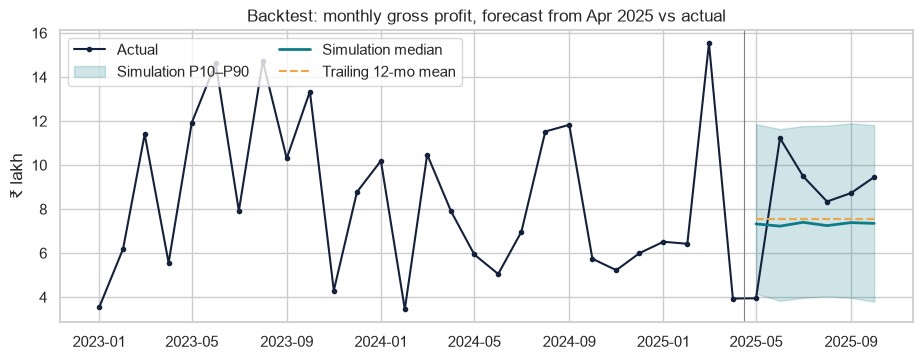

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
hist = monthly.gross_profit / 1e5
ax.plot(hist.index.to_timestamp(), hist.values, color=NAVY, marker="o", ms=3, label="Actual")
b = band(sim_bt["gross_profit"]) / 1e5
x = test_months.to_timestamp()
ax.fill_between(x, b.p10, b.p90, color=TEAL, alpha=.2, label="Simulation P10–P90")
ax.plot(x, b.p50, color=TEAL, lw=2, label="Simulation median")
ax.plot(x, baselines(train.gross_profit, 6)["Trailing 12-mo mean"] / 1e5, color=AMBER, ls="--", label="Trailing 12-mo mean")
ax.axvline(pd.Timestamp("2025-04-15"), color="grey", lw=.8); ax.set_ylabel("₹ lakh"); ax.legend(loc="upper left", ncols=2)
ax.set_title("Backtest: monthly gross profit, forecast from Apr 2025 vs actual")
save(fig, "q37_backtest")

## 3. Forecast Nov 2025 – Dec 2026 under three acquisition scenarios

In [6]:
P = estimate(pd.Period("2025-10", "M"), WINDOW)
h_mean = P["h_a"] / (P["h_a"] + P["h_b"]); c_mean = P["c_a"] / (P["c_a"] + P["c_b"]); q_mean = P["q_a"] / (P["q_a"] + P["q_b"])
print(f"Final inputs ({WINDOW}-month window): hazard {h_mean:.2%}/month, pool conversion {c_mean:.2%}/month, cancel {q_mean:.1%}, "
      f"avg profit/order ₹{P['pool_gp'].mean():,.0f}")
fc_months = pd.period_range("2025-11", "2026-12", freq="M")
SC = {"A": "A · No new sign-ups", "B": "B · Sign-ups resume (~7/mo)", "C": "C · Activation push (2x conversion)"}
sims = {k: simulate(P, fc_months, k, seed=SEED) for k in SC}

def yearly(sim, months, year):
    idx = [i for i, m in enumerate(months) if m.year == year]
    return {k: sim[k][:, idx].sum(axis=1) for k in ["orders", "rev_orders", "net_sales", "gross_profit", "new_buyers"]}

summary = []
for k, label in SC.items():
    y26 = yearly(sims[k], fc_months, 2026)
    for metric, arr in y26.items():
        p10, p50, p90 = np.percentile(arr, [10, 50, 90])
        summary.append(dict(scenario=label, metric=metric, p10=p10, p50=p50, p90=p90))
S = pd.DataFrame(summary)
display(S.pivot(index="metric", columns="scenario", values="p50").style.format("{:,.0f}"))

# monthly export for Power BI / reporting
rows = []
for k, label in SC.items():
    for metric in ["orders", "rev_orders", "net_sales", "gross_profit", "new_buyers"]:
        b = band(sims[k][metric])
        for i, m in enumerate(fc_months):
            rows.append(dict(scenario=label, month=m.to_timestamp(), metric=metric, **b.iloc[i].to_dict()))
pd.DataFrame(rows).to_csv(OUTPUT_DIR / "forecast_monthly.csv", index=False)

actual_2025_ytd = rev_o[rev_o.order_date.dt.year == 2025]
a26 = S[(S.scenario == SC["A"]) & (S.metric == "gross_profit")].iloc[0]
b26 = S[(S.scenario == SC["B"]) & (S.metric == "gross_profit")].iloc[0]
ns26 = S[(S.scenario == SC["A"]) & (S.metric == "net_sales")].iloc[0]
note(37, "2026 profit & sales",
     f"Scenario A (no new sign-ups): 2026 gross profit {L(a26.p50)} (80% range {L(a26.p10)}–{L(a26.p90)}), net sales {L(ns26.p50)}. "
     f"Scenario B (sign-ups resume): {L(b26.p50)}. For reference 2025 Jan-Oct actual was {L(actual_2025_ytd.gross_profit.sum())} "
     f"(about {L(actual_2025_ytd.gross_profit.sum() / 10 * 12)} annualised).")

Final inputs (12-month window): hazard 3.99%/month, pool conversion 2.93%/month, cancel 4.9%, avg profit/order ₹72,924


scenario,A · No new sign-ups,B · Sign-ups resume (~7/mo),C · Activation push (2x conversion)
metric,,,
gross_profit,"9,688,851","10,780,616","11,095,687"
net_sales,"35,877,019","40,005,997","41,159,938"
new_buyers,23,36,39
orders,139,155,160
rev_orders,132,148,152


Q37 · 2026 profit & sales: Scenario A (no new sign-ups): 2026 gross profit ₹96.9 L (80% range ₹79.9 L–₹115.4 L), net sales ₹358.8 L. Scenario B (sign-ups resume): ₹107.8 L. For reference 2025 Jan-Oct actual was ₹83.6 L (about ₹100.3 L annualised).


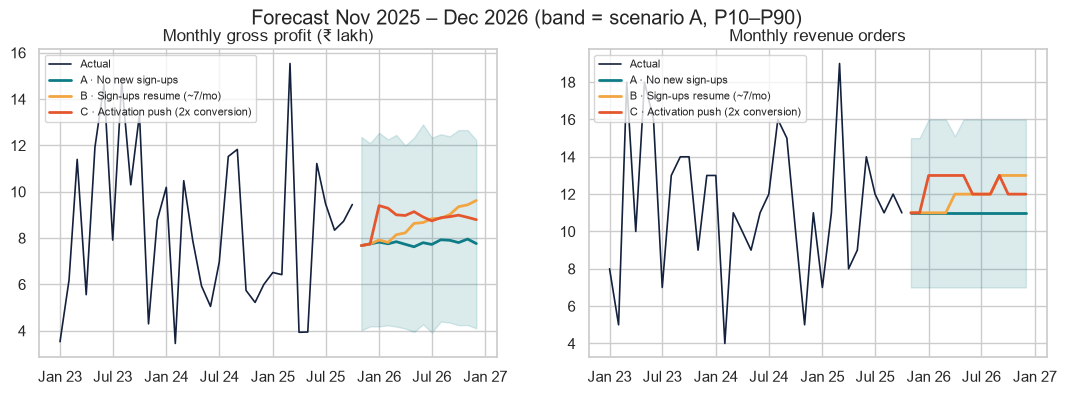

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, ttl, scale in [(axes[0], "gross_profit", "Monthly gross profit (₹ lakh)", 1e5), (axes[1], "rev_orders", "Monthly revenue orders", 1)]:
    h_ = monthly[metric] / scale
    ax.plot(h_.index.to_timestamp(), h_.values, color=NAVY, lw=1.2, label="Actual")
    for (k, label), col in zip(SC.items(), [TEAL, AMBER, CORAL]):
        b = band(sims[k][metric]) / scale
        x = fc_months.to_timestamp()
        ax.plot(x, b.p50, color=col, lw=2, label=label)
        if k == "A": ax.fill_between(x, b.p10, b.p90, color=col, alpha=.15)
    ax.set_title(ttl); ax.legend(fontsize=8, loc="upper left")
    ax.xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["DateFormatter"]).DateFormatter("%b %y"))
fig.suptitle("Forecast Nov 2025 – Dec 2026 (band = scenario A, P10–P90)")
save(fig, "q37_forecast")

### Q38 · Orders and active customers

In [8]:
o38 = S[S.metric.isin(["orders", "rev_orders"])].pivot(index="scenario", columns="metric", values="p50")
display(o38)
act = {k: np.percentile(sims[k]["active"][:, [i for i, m in enumerate(fc_months) if m.year == 2026]].mean(axis=1), 50) for k in SC}
note(38, "Orders",
     f"2026 revenue orders, median: A {o38.loc[SC['A'],'rev_orders']:.0f}, B {o38.loc[SC['B'],'rev_orders']:.0f}, "
     f"C {o38.loc[SC['C'],'rev_orders']:.0f} (2025 annualised ≈ {len(actual_2025_ytd)/10*12:.0f}). About {act['A']:.1f} customers "
     f"order in a typical month under A. The base keeps growing slowly because the existing 220 buyers keep repeating.")

metric,orders,rev_orders
scenario,,
A · No new sign-ups,139.00,132.00
B · Sign-ups resume (~7/mo),155.00,148.00
C · Activation push (2x conversion),160.00,152.00


Q38 · Orders: 2026 revenue orders, median: A 132, B 148, C 152 (2025 annualised ≈ 137). About 11.2 customers order in a typical month under A. The base keeps growing slowly because the existing 220 buyers keep repeating.


### Q39 · New-customer acquisition

In [9]:
nb = {k: np.percentile(sims[k]["new_buyers"].sum(axis=1), [10, 50, 90]) for k in SC}
pool_left_A = P["unconverted"] - np.median(sims["A"]["new_buyers"].sum(axis=1))
display(pd.DataFrame(nb, index=["p10", "p50", "p90"]).T.rename(index=SC))
share_rep = 1 - np.median(sims["A"]["new_buyers"][:, -12:].sum(axis=1) / sims["A"]["orders"][:, -12:].sum(axis=1))
note(39, "Acquisition",
     f"Nov 2025–Dec 2026 new buyers, median: A {nb['A'][1]:.0f}, B {nb['B'][1]:.0f}, C {nb['C'][1]:.0f}. Under A the unconverted pool "
     f"drains to about {pool_left_A:.0f} and {share_rep:.0%} of 2026 orders are repeat orders. "
     f"Without new sign-ups the business becomes almost purely a repeat business.")

,p10,p50,p90
A · No new sign-ups,20.00,27.00,34.00
B · Sign-ups resume (~7/mo),31.00,41.00,52.00
C · Activation push (2x conversion),34.00,43.00,52.00


Q39 · Acquisition: Nov 2025–Dec 2026 new buyers, median: A 27, B 41, C 43. Under A the unconverted pool drains to about 53 and 84% of 2026 orders are repeat orders. Without new sign-ups the business becomes almost purely a repeat business.


### Q40 · KPI: Profit per Active Customer in 2026 vs target

In [10]:
# Active customers in a year = distinct buyers with at least one revenue order (same as Power BI).
# Existing buyers are active with probability 1 - (1 - h(1-q))^months; newcomers if their first order is not cancelled.
def ppac_year(P, sim, months, year, scenario, rng):
    idx = [i for i, m in enumerate(months) if m.year == year]
    h = rng.beta(P["h_a"], P["h_b"], N_SIMS); q = rng.beta(P["q_a"], P["q_b"], N_SIMS)
    base_start = (len(P["buyers"]) + sim["new_buyers"][:, :idx[0]].sum(axis=1)).astype(int)
    # a buyer is "active" if at least one revenue order lands in the year: effective hazard h x (1 - q)
    existing_active = rng.binomial(base_start, 1 - (1 - h * (1 - q)) ** len(idx))
    newcomers = rng.binomial(sim["new_buyers"][:, idx].sum(axis=1).astype(int), 1 - q)
    return sim["gross_profit"][:, idx].sum(axis=1) / (existing_active + newcomers)

rng = np.random.default_rng(7)
# 2025 full-year PPAC = actual Jan-Oct profit + simulated Nov-Dec, over (actual Jan-Oct active + new Nov-Dec actives)
act25_custs = actual_2025_ytd.customer_id.nunique()
nd = [i for i, m in enumerate(fc_months) if m.year == 2025]
gp25 = actual_2025_ytd.gross_profit.sum() + sims["A"]["gross_profit"][:, nd].sum(axis=1)
h_draw = rng.beta(P["h_a"], P["h_b"], N_SIMS)
extra_active = rng.binomial(len(P["buyers"]) - act25_custs, 1 - (1 - h_draw) ** 2)  # buyers not yet active in 2025 who order in Nov-Dec
ppac25 = gp25 / (act25_custs + extra_active)
target26 = np.median(ppac25) * 1.05
res = {}
for k in SC:
    p26 = ppac_year(P, sims[k], fc_months, 2026, k, rng)
    res[SC[k]] = dict(p10=np.percentile(p26, 10), p50=np.median(p26), p90=np.percentile(p26, 90), prob_hit=(p26 >= target26).mean())
R = pd.DataFrame(res).T; display(R.style.format({"p10": "{:,.0f}", "p50": "{:,.0f}", "p90": "{:,.0f}", "prob_hit": "{:.0%}"}))
note(40, "PPAC KPI",
     f"Expected 2025 full-year PPAC ≈ ₹{np.median(ppac25):,.0f}, so the 2026 target (+5%) is ≈ ₹{target26:,.0f}. "
     f"Forecast 2026 PPAC under A: ₹{R.loc[SC['A'],'p50']:,.0f} (P10–P90 ₹{R.loc[SC['A'],'p10']:,.0f}–₹{R.loc[SC['A'],'p90']:,.0f}); "
     f"probability of hitting target: A {R.loc[SC['A'],'prob_hit']:.0%}, B {R.loc[SC['B'],'prob_hit']:.0%}, C {R.loc[SC['C'],'prob_hit']:.0%}. PPAC is a ratio, so it barely moves with acquisition "
     f"scenarios; it moves with order frequency, order value and margin.")

,p10,p50,p90,prob_hit
A · No new sign-ups,"74,501","92,247","113,821",24%
B · Sign-ups resume (~7/mo),"75,691","92,019","111,748",20%
C · Activation push (2x conversion),"75,950","92,737","112,091",22%


Q40 · PPAC KPI: Expected 2025 full-year PPAC ≈ ₹99,350, so the 2026 target (+5%) is ≈ ₹104,317. Forecast 2026 PPAC under A: ₹92,247 (P10–P90 ₹74,501–₹113,821); probability of hitting target: A 24%, B 20%, C 22%. PPAC is a ratio, so it barely moves with acquisition scenarios; it moves with order frequency, order value and margin.


### Q41 · Category demand (units) for 2026

In [11]:
i26 = [i for i, m in enumerate(fc_months) if m.year == 2026]
cu = sims["A"]["cat_units"][:, i26, :].sum(axis=1)
cat_fc = pd.DataFrame({"p10": np.percentile(cu, 10, axis=0), "p50": np.percentile(cu, 50, axis=0), "p90": np.percentile(cu, 90, axis=0)}, index=CATS)
last12 = lines[lines.is_revenue & (lines.order_date > DATA_END - pd.DateOffset(months=12))].groupby("category").quantity.sum()
cat_fc["last_12m_actual"] = last12
qtr = pd.DataFrame(np.median(np.stack([sims["A"]["cat_units"][:, [i for i in i26 if fc_months[i].quarter == qq], :].sum(axis=1)
                                        for qq in range(1, 5)], axis=1), axis=0), index=[f"2026 Q{qq}" for qq in range(1, 5)], columns=CATS)
display(cat_fc.style.format("{:,.0f}")); display(qtr.style.format("{:,.0f}"))
cat_fc.to_csv(OUTPUT_DIR / "forecast_category_units_2026.csv")
note(41, "Category demand",
     f"2026 units (scenario A, median): " + ", ".join(f"{c} {cat_fc.loc[c,'p50']:.0f}" for c in CATS) +
     f". Roughly {cat_fc.p50.sum()/4:.0f} units per quarter in total. Comparison with stock is not possible: "
     f"stock_quantity is a static snapshot unrelated to sales (audit Q15).")

,p10,p50,p90,last_12m_actual
Beauty,127,159,191,155
Electronics,102,129,159,127
Fashion,89,114,141,112
Home & Kitchen,89,113,139,111
Sports,114,144,178,142


,Beauty,Electronics,Fashion,Home & Kitchen,Sports
2026 Q1,39,32,28,28,35
2026 Q2,39,32,28,28,35
2026 Q3,40,32,28,28,35
2026 Q4,39,32,28,28,35


Q41 · Category demand: 2026 units (scenario A, median): Beauty 159, Electronics 129, Fashion 114, Home & Kitchen 113, Sports 144. Roughly 165 units per quarter in total. Comparison with stock is not possible: stock_quantity is a static snapshot unrelated to sales (audit Q15).


### Q42 · Cancellations and returns next quarter

In [12]:
q1 = [i for i, m in enumerate(fc_months) if m.year == 2026 and m.quarter == 1]
lost_orders = sims["A"]["orders"][:, q1].sum(axis=1) - sims["A"]["rev_orders"][:, q1].sum(axis=1)
gp_per_order = P["pool_gp"].mean()
lo = np.percentile(lost_orders, [10, 50, 90])
note(42, "Cancellations",
     f"Cancel/return rate posterior mean {q_mean:.1%}. 2026 Q1: median {lo[1]:.0f} lost orders (P10–P90 {lo[0]:.0f}–{lo[2]:.0f}), "
     f"≈ {L(lo[1] * gp_per_order)} profit forgone. Too few events to model drivers; track the rate monthly against ~5%.")

Q42 · Cancellations: Cancel/return rate posterior mean 4.9%. 2026 Q1: median 1 lost orders (P10–P90 0–3), ≈ ₹0.7 L profit forgone. Too few events to model drivers; track the rate monthly against ~5%.


## Power BI exports

In [13]:
NAMES = {"gross_profit": "Gross profit", "net_sales": "Net sales", "rev_orders": "Revenue orders", "new_buyers": "New buyers"}
first_month = orders[orders.n == 1].groupby("m").size()
act = (rev_o.groupby("m").agg(gross_profit=("gross_profit", "sum"), net_sales=("net_sales", "sum"), rev_orders=("order_id", "count"))
       .join(first_month.rename("new_buyers")).reindex(pd.period_range("2023-01", "2025-10", freq="M")).fillna(0))
rows = []
for k, label in SC.items():
    for metric, nice in NAMES.items():
        for m, v in act[metric].items():
            rows.append(dict(scenario=label, month=m.to_timestamp(), metric=nice, kind="Actual", actual=v, p10=None, p50=None, p90=None))
        b = band(sims[k][metric])
        for i, m in enumerate(fc_months):
            rows.append(dict(scenario=label, month=m.to_timestamp(), metric=nice, kind="Forecast", actual=None, **b.iloc[i].to_dict()))
pd.DataFrame(rows).to_csv(OUTPUT_DIR / "pbi_forecast.csv", index=False, date_format="%Y-%m-%d")
ann = S.assign(metric=S.metric.map({**NAMES, "orders": "Orders placed"})).copy()
for label, r in R.iterrows():
    ann = pd.concat([ann, pd.DataFrame([dict(scenario=label, metric="PPAC", p10=r.p10, p50=r.p50, p90=r.p90),
                                        dict(scenario=label, metric="PPAC target", p10=target26, p50=target26, p90=target26),
                                        dict(scenario=label, metric="P(PPAC hits target)", p10=r.prob_hit, p50=r.prob_hit, p90=r.prob_hit)])])
ann.to_csv(OUTPUT_DIR / "pbi_forecast_2026.csv", index=False)
print(len(rows), "monthly rows;", len(ann), "annual rows")

576 monthly rows; 24 annual rows


## Summary

In [14]:
F = pd.DataFrame(findings); F.to_csv(OUTPUT_DIR / "forecast_findings.csv", index=False)
pd.set_option("display.max_colwidth", None); F

,q,topic,finding
0,37,Backtest,"6-month holdout (May-Oct 2025) gross profit: actual ₹51.2 L. Customer-base simulation forecast ₹46.0 L (-10%, median of 6-month totals) using a 12-month history window. Every window under-forecast this period (12m -10%, 18m -13%, 24m -8%), so the model is mildly conservative; the actual total sat inside the 80% interval. Best monthly MAE: Exp. smoothing (SES) (₹1.6 L/month). Monthly errors are large for every method (noise ~41% CV); totals over 6+ months are reliable, single months are not."
1,37,2026 profit & sales,"Scenario A (no new sign-ups): 2026 gross profit ₹96.9 L (80% range ₹79.9 L–₹115.4 L), net sales ₹358.8 L. Scenario B (sign-ups resume): ₹107.8 L. For reference 2025 Jan-Oct actual was ₹83.6 L (about ₹100.3 L annualised)."
2,38,Orders,"2026 revenue orders, median: A 132, B 148, C 152 (2025 annualised ≈ 137). About 11.2 customers order in a typical month under A. The base keeps growing slowly because the existing 220 buyers keep repeating."
3,39,Acquisition,"Nov 2025–Dec 2026 new buyers, median: A 27, B 41, C 43. Under A the unconverted pool drains to about 53 and 84% of 2026 orders are repeat orders. Without new sign-ups the business becomes almost purely a repeat business."
4,40,PPAC KPI,"Expected 2025 full-year PPAC ≈ ₹99,350, so the 2026 target (+5%) is ≈ ₹104,317. Forecast 2026 PPAC under A: ₹92,247 (P10–P90 ₹74,501–₹113,821); probability of hitting target: A 24%, B 20%, C 22%. PPAC is a ratio, so it barely moves with acquisition scenarios; it moves with order frequency, order value and margin."
5,41,Category demand,"2026 units (scenario A, median): Beauty 159, Electronics 129, Fashion 114, Home & Kitchen 113, Sports 144. Roughly 165 units per quarter in total. Comparison with stock is not possible: stock_quantity is a static snapshot unrelated to sales (audit Q15)."
6,42,Cancellations,"Cancel/return rate posterior mean 4.9%. 2026 Q1: median 1 lost orders (P10–P90 0–3), ≈ ₹0.7 L profit forgone. Too few events to model drivers; track the rate monthly against ~5%."
